# After the fit: quality control, uncertainty and differential expression

Fitting a model gives one parameter set per gene. This notebook shows what Monod
offers for the steps that follow: rejecting genes the model does not describe,
reading the standard errors, and comparing two datasets parameter by parameter
rather than by mean expression.

The two groups are the **T cells** and **monocytes** of the PBMC 10k
experiment, fitted from one `AnnData` with `split_by` on the cell-type label.
The same genes are fitted in both, with the `Bursty` transcription model and
no sequencing-noise model, so each gene has three parameters: burst size *b*,
splicing rate *β* and degradation rate *γ* (all log10, in units of the
transcription-burst frequency).

| Section | Function |
|---|---|
| 2 | `perform_inference(split_by=...)` on an in-memory `AnnData` |
| 3 | `.varm` tables, `analysis.group_result`, `searchdata_from_adata` |
| 4 | `inference.reject_genes`, `SearchResults.plot_KL`, `plot_gene_distributions` |
| 5 | `SearchResults.compute_sigma`, `plot_param_marg`, `analysis.plot_params_for_pair` |
| 6 | `analysis.DE_parameters` |
| 7 | `analysis.group_search_data`, `analysis.diffexp_mean` |
| 8 | `analysis.compare_gene_distributions` |
| 9 | `AnnData.write_h5ad`, `analysis.group_result` on the reloaded object |

**Data:** `example_h5ad/processed_pbmc_10k_raw.h5ad` (not in the repository).
**Runtime:** under a minute with the Rust accelerator.

In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))

In [2]:
import logging, time, warnings
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt

from monod import analysis
from monod.cme_toolbox import CMEModel, _HAS_RUST
from monod.inference import perform_inference, reject_genes, searchdata_from_adata

logging.getLogger('monod').setLevel(logging.WARNING)   # progress messages off
warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)
print(f'Rust backend: {_HAS_RUST}')

Rust backend: True


---
## 1 · Two cell types from one experiment

The processed PBMC 10k object carries raw unspliced and spliced counts and a
cell-type label in `obs['subclass_label']`. Both cell types stay in the one
object: `perform_inference` splits on the label itself. Gene symbols are moved
into the index so that the result tables read naturally.


In [3]:
H5AD_PATH = 'example_h5ad/processed_pbmc_10k_raw.h5ad'
adata = ad.read_h5ad(H5AD_PATH)
adata.var_names = adata.var['gene_name'].astype(str).values
adata.var_names_make_unique()

GROUPS = ['Tcells', 'Monocytes']     # fitted in this order: fold changes read monocytes minus T cells
print(adata.obs['subclass_label'].value_counts().to_string())

subclass_label
Tcells       5375
Monocytes    3972
Bcells       1650


---
## 2 · Fit both groups in one call

`split_by` names the `obs` column and `groups` picks the two labels to fit, in
that order (the B cells are left out). The genes are selected once on all the
cells kept, so the two fits line up gene for gene; each group is then fitted on
its own cells, with its own grid limits. One more argument matters for what
follows: `exclude_sigma=False` computes a standard error for every parameter
from the Hessian at the optimum, which the differential-expression test in
section 6 uses.

With a sequencing-noise model (`Poisson` or `Bernoulli`) each group would
repeat its fit over a grid of technical parameters, and one grid point would be
chosen for all the groups: the one that minimises their summed divergence,
each group weighted by its cell count. Capture efficiencies belong to the
experiment, not to the cell type, so that is the default; `shared_samp=False`
lets each group pick its own point, and `SearchResults.plot_landscape` shows
the grid. Without a noise model there is a single grid point and the step is
skipped. When one object holds several experiments, `batch_by` names their
column: every (cell type, experiment) pair is fitted and the optimum is shared
within each experiment only.


In [4]:
N_GENES = 200
model = CMEModel('Bursty', 'None')

t0 = time.perf_counter()
adata = perform_inference(adata, model, split_by='subclass_label', groups=GROUPS, n_genes=N_GENES,
                          exclude_sigma=False, viz=False, dataset_string='pbmc', num_cores=8)
print(f'{adata.n_vars} genes fitted in {len(GROUPS)} groups in {time.perf_counter() - t0:.1f} s')
print(adata.uns['split_by'])
print(adata.obs['subclass_label'].value_counts().to_string())

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

optimize_genes_2d_sd: 4/200 genes did not converge (4 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


Grid scan: 100%|██████████| 1/1 [00:00<00:00,  2.79it/s]

Grid scan: 100%|██████████| 1/1 [00:00<00:00,  2.79it/s]

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

optimize_genes_2d_sd: 8/200 genes did not converge (8 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


Grid scan: 100%|██████████| 1/1 [00:00<00:00,  3.12it/s]

Grid scan: 100%|██████████| 1/1 [00:00<00:00,  3.11it/s]

200 genes fitted in 2 groups in 11.3 s
{'column': 'subclass_label', 'groups': ['Tcells', 'Monocytes'], 'keys': ['Tcells', 'Monocytes']}
subclass_label
Tcells       5375
Monocytes    3972


---
## 3 · What the fit leaves behind

Each group has a per-gene table in `.varm`, keyed by its label: the log10
parameter estimates under the model's TeX labels (`$b$`, `$\beta$`, `$\gamma$`),
their standard errors (`error_*`) and the AIC. The result objects are plain
dictionaries in `.uns['search_result_list']`; `analysis.group_result` turns one
back into a `SearchResults`, and `searchdata_from_adata` rebuilds the per-gene
histograms of the whole object. The plotting and testing methods take that full
search data and restrict it to their own group's cells.


In [5]:
display(adata.varm['Tcells'].head(6).round(3))

sr_T, sr_M = (analysis.group_result(adata, g) for g in GROUPS)
sd = searchdata_from_adata(adata)
print(f'genes: {sr_T.n_genes}   cells: {sr_T.n_cells:,} T cells, {sr_M.n_cells:,} monocytes   '
      f'parameters per gene: {sr_T.sp.n_phys_pars}   grid points: {sr_T.sp.n_grid_points}')

,$b$,$\beta$,$\gamma$,AIC,error_$b$,error_$\beta$,error_$\gamma$,error_unreliable
TGFBR3,0.976,0.482,1.819,26551.322,0.016,0.011,0.021,False
RAB3GAP2,-0.055,0.004,0.719,19146.772,0.022,0.020,0.026,False
FAAH,-0.886,1.064,1.049,1334.838,0.161,0.157,0.164,False
TNFRSF8,-0.300,1.434,2.390,1071.646,0.121,0.108,0.180,False
S100A11,-0.619,1.154,-0.004,7482.510,0.056,0.068,0.055,False
TPM3,-0.028,-0.013,-0.208,32824.653,0.016,0.016,0.016,False


genes: 200   cells: 5,375 T cells, 3,972 monocytes   parameters per gene: 3   grid points: 1


---
## 4 · Goodness of fit and gene rejection

`reject_genes` runs a chi-square test of each gene's observed joint histogram
against its fitted distribution (Bonferroni-corrected, with low-count bins
pooled) and a Hellinger-distance check, group by group, then flags the failures
in each group's table (`rejected_genes`) and inside the stored results. Later
functions skip rejected genes by default (`discard_rejected=True`).

`plot_KL` shows the distribution of per-gene divergences, and
`plot_gene_distributions` the observed and fitted joint distributions. Below,
the top row holds the four worst T-cell fits by Hellinger distance and the
bottom row the four best.


Tcells    :  33 of 200 genes rejected
Monocytes :  38 of 200 genes rejected


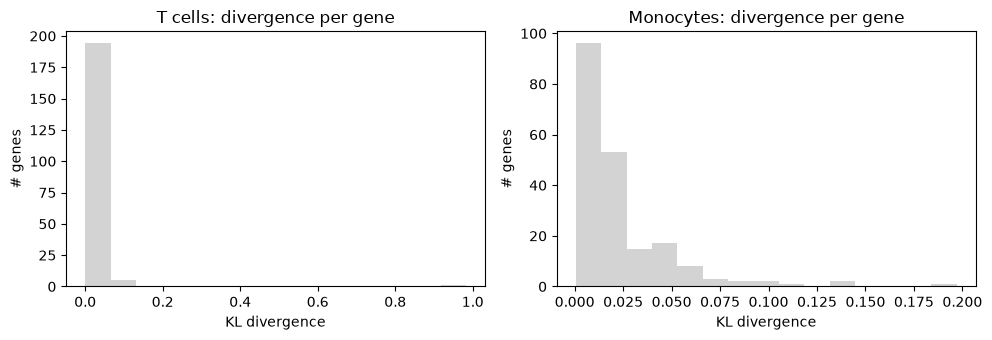

Worst fits: ['RPS27', 'RBM47', 'MARCKS', 'FGR']  rejected: [True, True, True, True]
Best fits : ['OSBPL7', 'C20orf96', 'GMPR', 'GRIN2D']


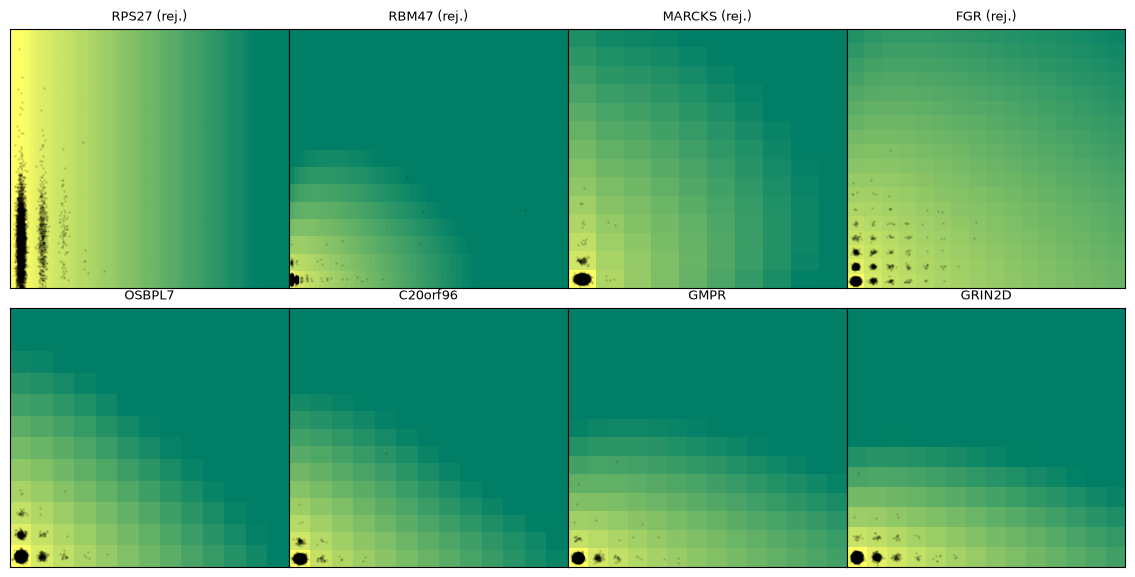

In [6]:
reject_genes(adata, viz=False)
for g in GROUPS:
    print(f"{g:10s}: {int(adata.varm[g]['rejected_genes'].sum()):3d} of {adata.n_vars} genes rejected")

# Reload the results so the objects carry the rejection flags.
sr_T, sr_M = (analysis.group_result(adata, g) for g in GROUPS)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, sr, name in zip(axes, (sr_T, sr_M), ('T cells', 'Monocytes')):
    sr.plot_KL(ax, discard_rejected=False)
    ax.set_title(f'{name}: divergence per gene')
plt.tight_layout(); plt.show()

tab_T = adata.varm['Tcells']
order = np.argsort(tab_T['hellinger'].values)
worst, best = order[-4:][::-1], order[:4]
print('Worst fits:', list(adata.var_names[worst]), ' rejected:', [bool(v) for v in tab_T['rejected_genes'].values[worst]])
print('Best fits :', list(adata.var_names[best]))
sr_T.plot_gene_distributions(sd, sz=(2, 4), figsize=(12, 6), marg='joint',
                             genes_to_plot=np.concatenate([worst, best]), savefig=False)
plt.show()

---
## 5 · Parameter uncertainty and the pair plot

`compute_sigma` inverts the Hessian of the divergence at each gene's optimum to
get a local standard error per parameter; `perform_inference` already did this
and stored the values in each group's table (`error_*`). `plot_param_marg`
shows the distribution of each parameter across genes, and
`plot_params_for_pair` puts the two groups against each other with error bars.
That picture is what the differential-expression test in the next section
formalises: most genes near the identity line, possibly with a small common
offset, and a few far from it.


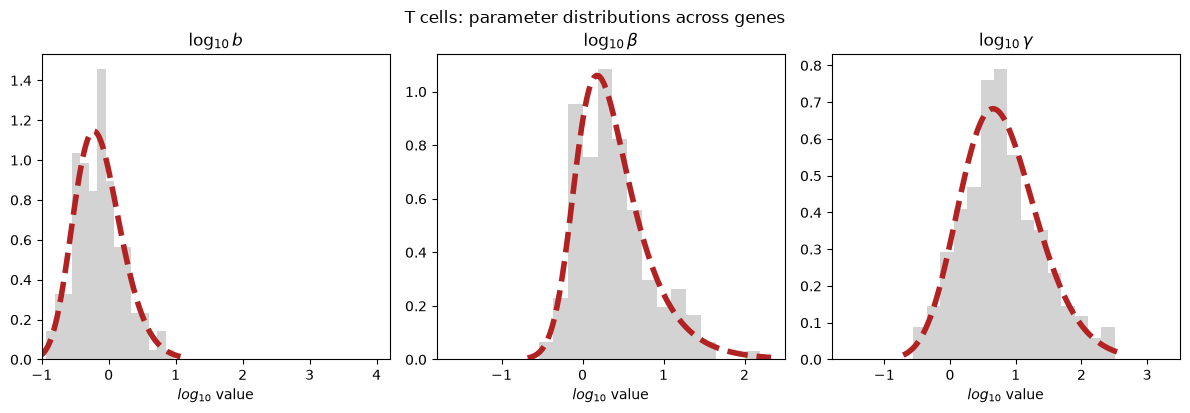

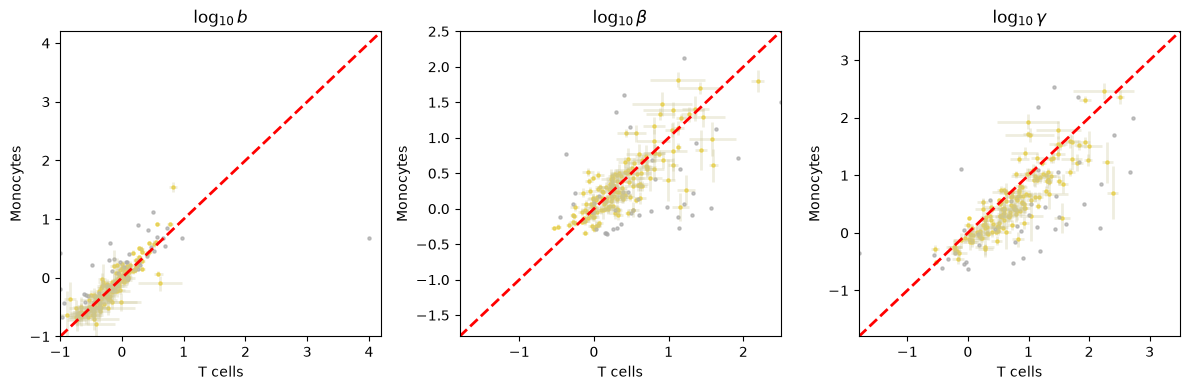

Median standard error (log10 units) per parameter, T cells:
error_$b$         0.029
error_$\beta$     0.026
error_$\gamma$    0.033


In [7]:
sr_T.plot_param_marg()
plt.suptitle('T cells: parameter distributions across genes', y=1.02)
plt.show()

fig = analysis.plot_params_for_pair(sr_T, sr_M, plot_errorbars=True,
                                    xlabel='T cells', ylabel='Monocytes', savefig=False)
fig.savefig('figures/analysis_workflow_pair.png', dpi=150, bbox_inches='tight')
plt.show()

err_cols = [c for c in adata.varm['Tcells'].columns if c.startswith('error_') and c != 'error_unreliable']
print('Median standard error (log10 units) per parameter, T cells:')
print(adata.varm['Tcells'][err_cols].median().round(3).to_string())

---
## 6 · Differential expression, one parameter at a time

`DE_parameters` on the split object compares every pair of groups parameter by
parameter. For each parameter it models the gene-to-gene differences as a
Gaussian around a common offset, weighted by the standard errors, and iterates:
genes whose difference is improbable under that Gaussian are set aside, the
Gaussian is refitted on the rest, and so on. The genes left outside at
convergence are called differentially expressed with respect to that parameter.
Rejected genes are excluded first. The histograms show the residuals after the
last round, with the fitted Gaussian.

It returns, keyed by the pair of group labels, the gene names per parameter, a
boolean matrix, the fitted offsets and the residuals, and writes fold changes
into both groups' tables: `FC_*_vs_<other>` (raw difference, second group minus
first) and `adj_FC_*_vs_<other>` (difference minus the common offset).


Groups: ('Tcells', 'Monocytes')


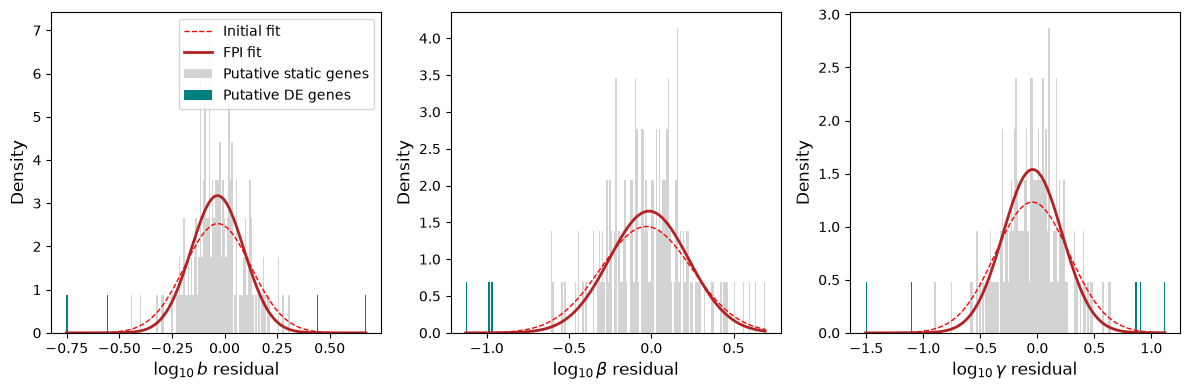

Fold changes recorded in .varm['Monocytes'] and .varm['Tcells'], e.g. FC_$\gamma$_vs_Tcells (and adj_FC_$\gamma$_vs_Tcells without the common offset); second group minus first.
Common offset (monocytes minus T cells, log10): {'$b$': 0.043, '$\\beta$': 0.002, '$\\gamma$': -0.183}
Genes called DE per parameter: {'$b$': 4, '$\\beta$': 3, '$\\gamma$': 5}


,gene,adj_FC_$b$,DE_$b$,adj_FC_$\beta$,DE_$\beta$,adj_FC_$\gamma$,DE_$\gamma$,n_DE
91,SLC16A5,-0.183,False,-0.974,True,-1.110,True,2
37,ST8SIA6,-0.752,True,0.278,False,0.405,False,1
3,TNFRSF8,0.178,False,-0.607,False,-1.506,True,1
179,MTSS1,0.672,True,-0.260,False,0.028,False,1
97,POLG2,-0.560,True,-0.082,False,-0.443,False,1
78,CDR2,0.148,False,0.223,False,0.899,True,1
38,AL513303.1,-0.325,False,0.322,False,1.119,True,1
127,PLAGL2,0.441,True,-0.592,False,-0.435,False,1
136,RRP1,0.128,False,-1.129,True,0.357,False,1
138,CENPM,-0.296,False,0.692,False,0.863,True,1


In [8]:
de = analysis.DE_parameters(adata, use_sigma=True, viz=True)
plt.show()
pair = tuple(GROUPS)
gn, gf, offs, resid = (d[pair] for d in de)

par_labels = [p.replace(r'\log_{10} ', '') for p in sr_T.model.param_str]
print('Common offset (monocytes minus T cells, log10):',
      {k: round(float(v), 3) for k, v in zip(par_labels, offs[:, 0])})
print('Genes called DE per parameter:', {k: int(v) for k, v in zip(par_labels, gf.sum(1))})

tab_M = adata.varm['Monocytes']
tab = pd.DataFrame({'gene': adata.var_names})
for i, lab in enumerate(par_labels):
    tab['adj_FC_' + lab] = tab_M['adj_FC_' + lab + '_vs_Tcells'].values
    tab['DE_' + lab] = gf[i]
rejected = adata.varm['Tcells']['rejected_genes'].values | tab_M['rejected_genes'].values
tab = tab.loc[~rejected].copy()
tab['n_DE'] = tab[[c for c in tab.columns if c.startswith('DE_')]].sum(1)
display(tab.sort_values('n_DE', ascending=False).head(12).round(3))

---
## 7 · Against the mean-expression view

`diffexp_mean` is the conventional comparison on the same cells: a Welch t-test
on size-normalised, log-transformed spliced counts, with a Bonferroni-corrected
threshold and a minimum absolute log2 fold change (`fc_thr`, 1 by default).
The two tests need not agree. The t-test asks whether a gene's mean moved by
more than the threshold; the parameter test asks whether a gene's shift in one
parameter stands out against the shifts of all other genes, after the common
offset is removed. A gene can change burst size and degradation rate in
compensating directions and keep its mean, and a gene whose mean moves along
with most other genes is not singled out by the parameter test.

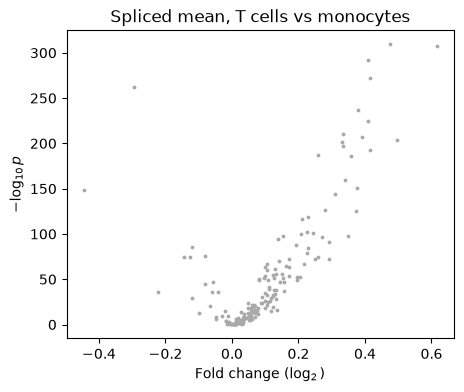

DE in any parameter,False,True
DE by mean (t-test),,
False,148,11


DE in a parameter but not in mean: ['TNFRSF8', 'ST8SIA6', 'AL513303.1', 'CDR2', 'SLC16A5', 'POLG2', 'PLAGL2', 'RRP1', 'CENPM', 'MTSS1', 'NHS']


In [9]:
sd_T, sd_M = (analysis.group_search_data(adata, g, sd) for g in GROUPS)

fig, ax = plt.subplots(figsize=(5, 4))
gf_mean, fc_mean = analysis.diffexp_mean(sd_T, sd_M, method='ttest', viz=True, ax1=ax)
ax.set_title('Spliced mean, T cells vs monocytes')
plt.show()

keep = ~rejected
ct = pd.crosstab(pd.Series(gf_mean[keep], name='DE by mean (t-test)'),
                 pd.Series(gf.any(0)[keep], name='DE in any parameter'))
display(ct)

only_params = tab.loc[(tab['n_DE'] > 0) & ~gf_mean[keep], 'gene'].tolist()
print('DE in a parameter but not in mean:', only_params[:15])

---
## 8 · Look at the genes

`compare_gene_distributions` overlays the two groups' marginal histograms and
fitted marginals for a chosen set of genes (T cells in blue, monocytes in red).
Here: six genes called DE in at least one parameter, ranked by their largest
adjusted change over the three parameters.


,adj_FC_$b$,adj_FC_$\beta$,adj_FC_$\gamma$,n_DE
gene,,,,
TNFRSF8,0.18,-0.61,-1.51,1
RRP1,0.13,-1.13,0.36,1
AL513303.1,-0.32,0.32,1.12,1
SLC16A5,-0.18,-0.97,-1.11,2
NHS,0.28,-0.99,-0.89,1
CDR2,0.15,0.22,0.90,1


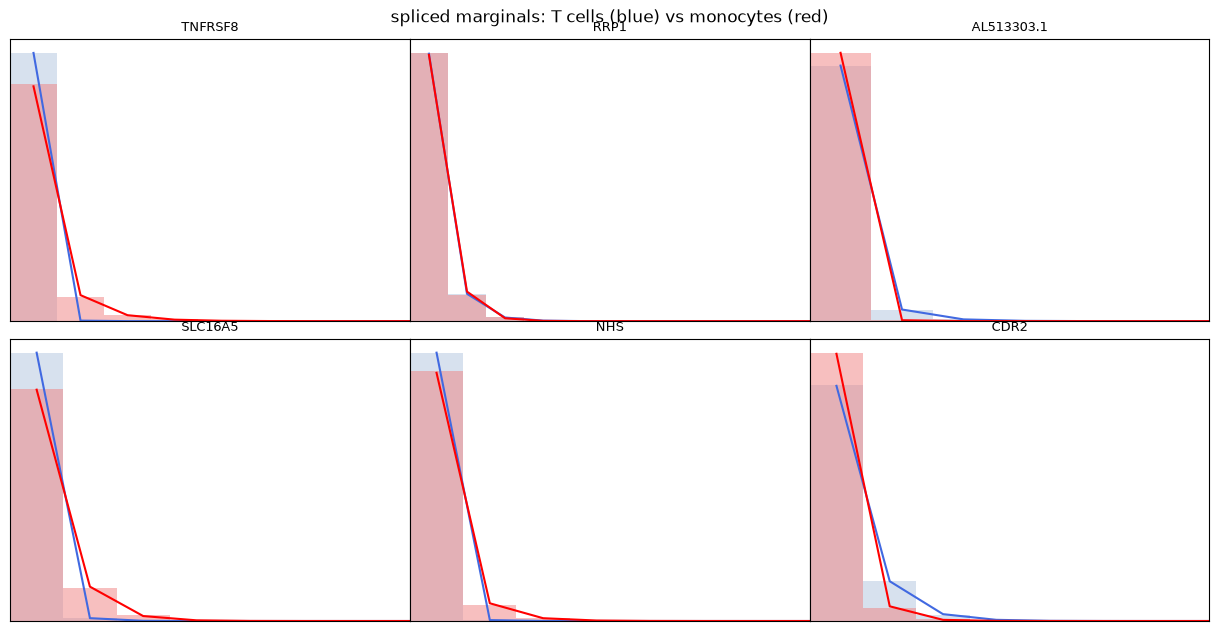

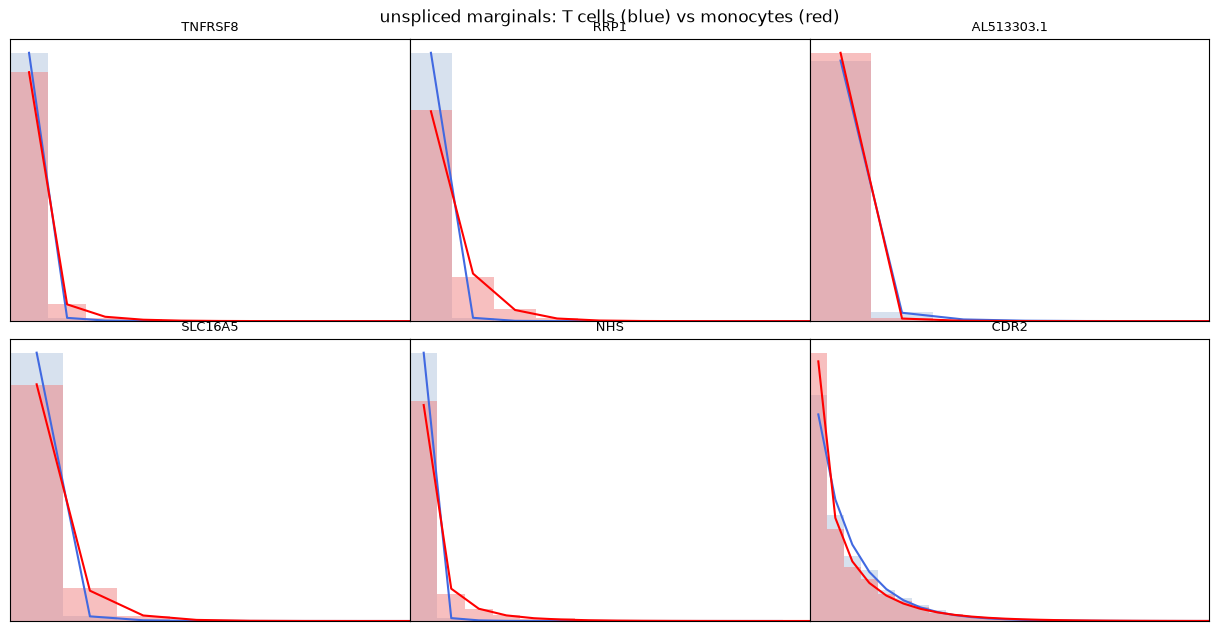

In [10]:
fc_cols = ['adj_FC_' + lab for lab in par_labels]
cand = tab.loc[tab['n_DE'] > 0] if (tab['n_DE'] > 0).any() else tab
top = cand.reindex(cand[fc_cols].abs().max(1).sort_values(ascending=False).index).head(6)
idx = np.array([list(adata.var_names).index(g) for g in top['gene']])
display(top[['gene'] + fc_cols + ['n_DE']].round(2).set_index('gene'))

for marg in ('spliced', 'unspliced'):
    analysis.compare_gene_distributions([sr_T, sr_M], [sd_T, sd_M], sz=(2, 3), figsize=(12, 6),
                                        marg=marg, genes_to_plot=idx)
    plt.suptitle(f'{marg} marginals: T cells (blue) vs monocytes (red)', y=1.02)
    plt.show()

---
## 9 · Saving and reloading

Everything above lives in the one `AnnData`: the tables in `.varm`, the results
in `.uns`, all plain arrays and dictionaries, so `write_h5ad` is all that is
needed to keep it. Reading the file back and calling `analysis.group_result`
restores a group's result object, including the standard errors and the
rejection flags.


In [11]:
out_dir = 'figures/analysis_workflow'
os.makedirs(out_dir, exist_ok=True)
adata.write_h5ad(f'{out_dir}/pbmc_T_vs_M_fit.h5ad')

back = ad.read_h5ad(f'{out_dir}/pbmc_T_vs_M_fit.h5ad')
sr_back = analysis.group_result(back, 'Monocytes')
print('groups              :', list(back.uns['split_by']['groups']))
print('fold-change columns :', [c for c in back.varm['Monocytes'].columns if c.startswith('adj_FC_')])
print('rejected genes      :', int(sr_back.rejected_genes.sum()))
print('standard errors kept:', np.allclose(sr_back.sigma, sr_M.sigma))

groups              : ['Tcells', 'Monocytes']
fold-change columns : ['adj_FC_$b$_vs_Tcells', 'adj_FC_$\\beta$_vs_Tcells', 'adj_FC_$\\gamma$_vs_Tcells']
rejected genes      : 38
standard errors kept: True


---
## Summary

| Step | Call | Writes |
|---|---|---|
| Fit | `perform_inference(adata, model, split_by='subclass_label', groups=[...], exclude_sigma=False)` | `.varm[<group>]` parameters, `error_*`, `AIC`; `.uns['search_result_list']`, `.uns['split_by']` |
| Rejection | `reject_genes(adata)` | `.varm[<group>]['rejected_genes', 'csq', 'pval', 'hellinger']` |
| Parameter DE | `DE_parameters(adata)` | `.varm[<group>]['FC_*_vs_<other>', 'adj_FC_*_vs_<other>']` |
| Mean DE | `diffexp_mean(sd1, sd2)` | returns flags and log2 fold changes |

Two separate objects, for instance two experiments in two files, go through the
same steps with `DE_parameters(adata1, adata2)`, which writes `FC_*` and
`adj_FC_*` into each object's `.var`. The meK-Means variant, where the groups
are clusters the model finds rather than labels, is the subject of
`mek_means.ipynb`.
